# Bab 8 — Tree-Based Algorithms and Ensemble Methods

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025)

---


| No | Resep | Kelas scikit-learn | Ide utama |
|----|-------|--------------------|-----------|
| 1 | Pengantar pohon keputusan | `DecisionTreeClassifier`, `plot_tree` | pemisahan rekursif dengan Gini/entropi |
| 2 | Random Forest & bagging | `RandomForestClassifier` | rata-rata banyak pohon independen → varians turun |
| 3 | Gradient Boosting | `GradientBoostingClassifier` | pohon berurutan memperbaiki galat → bias turun |
| 4 | Tuning hyperparameter | `GridSearchCV` | `n_estimators`, `max_depth`, `learning_rate` |
| 5 | Membandingkan ensemble | `StackingClassifier` | bagging vs boosting vs stacking |
| 6 | Latihan | Wine, Breast Cancer, Digits | |

## Resep 1 — Pengantar Pohon Keputusan

### Teori
Pohon keputusan membagi ruang fitur secara rekursif menjadi kotak-kotak (*axis-aligned*). Setiap simpul internal menguji satu fitur terhadap ambang ($x_j \le t$), dan setiap daun memberi prediksi (kelas mayoritas atau rata-rata).

**Memilih pemisahan terbaik.** Algoritma CART (yang dipakai scikit-learn) mencoba semua fitur $j$ dan ambang $t$, lalu memilih pasangan yang paling menurunkan **impurity**. Untuk simpul dengan proporsi kelas $p_k$:
- **Gini impurity:** $G = 1 - \sum_{k} p_k^2$ — peluang salah klasifikasi jika label ditebak acak sesuai proporsi simpul. Default scikit-learn.
- **Entropi:** $H = -\sum_k p_k\log_2 p_k$ — ketidakpastian informasi.

Keduanya bernilai 0 untuk simpul murni. Kualitas pemisahan diukur dengan penurunan impurity tertimbang (**information gain** bila memakai entropi):
$$\Delta = I(\text{induk}) - \frac{n_L}{n}I(\text{kiri}) - \frac{n_R}{n}I(\text{kanan})$$

Proses berlanjut secara **greedy** (terbaik secara lokal di setiap langkah) hingga daun murni atau kriteria berhenti terpenuhi (`max_depth`, `min_samples_split`, `min_samples_leaf`, ...).

**Kelebihan:** mudah diinterpretasikan, tidak butuh scaling, menangkap interaksi dan non-linearitas. **Kekurangan:** tanpa batasan, pohon tumbuh sampai menghafal data latih (overfitting/varians tinggi), dan perubahan kecil pada data bisa menghasilkan pohon yang sangat berbeda (tidak stabil).

In [ ]:
# Load libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [ ]:
# Instantiate the model
clf = DecisionTreeClassifier(random_state=2024)

# Fit the model to the training data
clf.fit(X_train, y_train)

# Generate predictions
y_pred = clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

# Create a classification report
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

# Stylize the DataFrame
styled_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

styled_df

,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


In [ ]:
print('Akurasi pohon keputusan: %.3f' % accuracy)
print('Kedalaman pohon: %d | jumlah daun: %d' % (clf.get_depth(), clf.get_n_leaves()))
print('Akurasi latih  : %.3f' % clf.score(X_train, y_train))

# Contoh perhitungan Gini pada simpul akar (proporsi kelas data latih)
p = np.bincount(y_train) / len(y_train)
print('Proporsi kelas di akar:', p.round(3), '-> Gini = %.3f' % (1 - np.sum(p ** 2)))

Akurasi pohon keputusan: 0.867
Kedalaman pohon: 4 | jumlah daun: 5
Akurasi latih  : 1.000
Proporsi kelas di akar: [0.305 0.362 0.333] -> Gini = 0.665


**Interpretasi.** Pohon tanpa batasan mencapai akurasi latih **1,000** (setiap daun murni), tetapi akurasi uji hanya **0,867** (39 dari 45). Selisih ini adalah tanda klasik **overfitting**. Semua 18 *setosa* benar; 6 kesalahan seluruhnya terjadi antara *versicolor* dan *virginica* (2 versicolor → virginica, 4 virginica → versicolor). Pohon cukup dangkal (kedalaman 4, 5 daun) karena Iris sederhana, tetapi ambang-ambang di bagian bawah pohon dipilih berdasarkan segelintir sampel latih yang tidak mewakili data uji.

Gini di simpul akar = $1 - (0{,}305^2 + 0{,}362^2 + 0{,}333^2) \approx 0{,}665$, mendekati maksimum $1 - 1/3 \approx 0{,}667$ untuk 3 kelas seimbang — titik awal dengan ketidakpastian maksimum.

### Visualisasi pohon

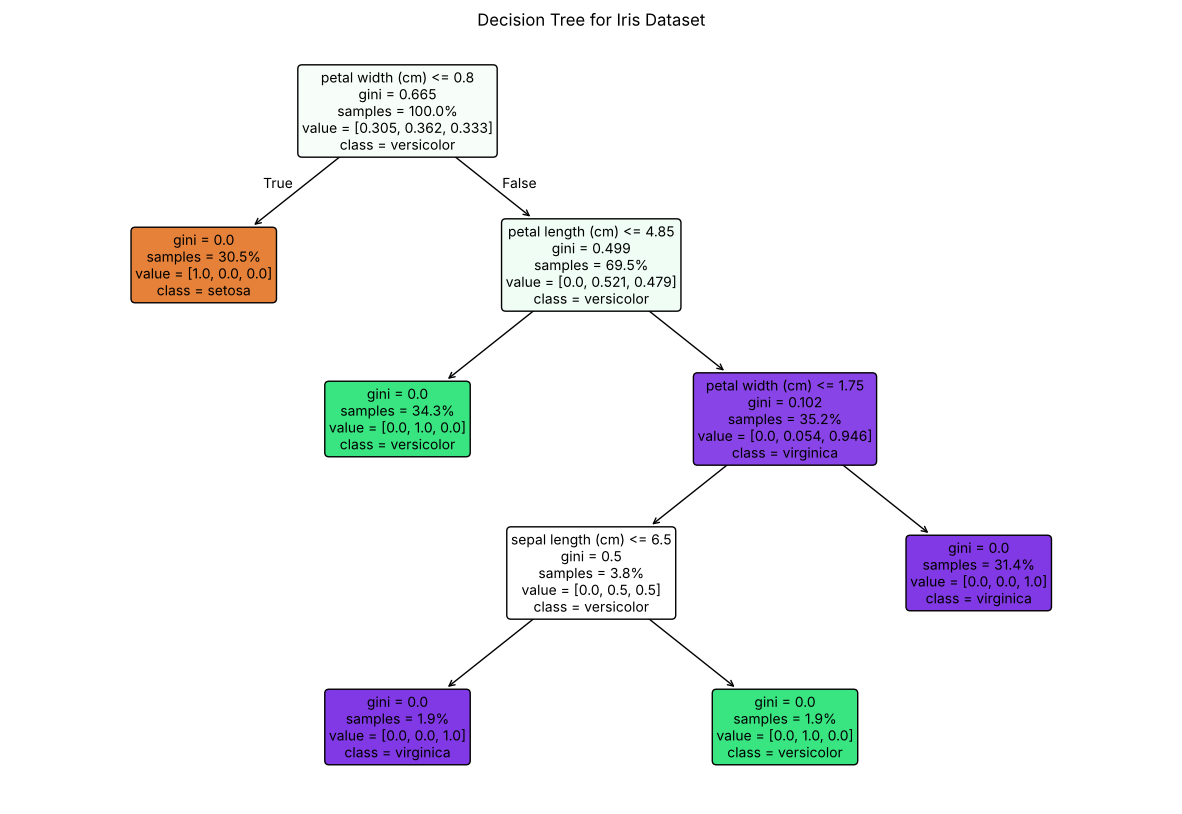

In [ ]:
# Load the libraries
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Plot the figure
plt.figure(figsize=(15,10))
plot_tree(clf, feature_names=iris.feature_names, class_names=iris.target_names, filled=True, proportion=True, rounded=True, fontsize=10)
plt.title("Decision Tree for Iris Dataset")
plt.show()

**Interpretasi.** Cara membaca pohon dari atas:
1. **Akar:** `petal width ≤ 0.8` langsung memisahkan seluruh *setosa* (30,5% data) ke daun murni dengan Gini = 0.
2. Sisanya (69,5%, Gini ≈ 0,499 — hampir 50:50 *versicolor* vs *virginica*) dipisah dengan `petal length ≤ 4.85`: cabang kiri menjadi daun *versicolor* murni.
3. Cabang kanan dipisah lagi dengan `petal width ≤ 1.75`, menghasilkan daun *virginica* murni (31,4%) dan simpul kecil berisi 3,8% data.
4. Simpul kecil terakhir dipisah dengan `sepal length ≤ 6.5` menjadi dua daun yang masing-masing hanya berisi **1,9% data (2 sampel)**.

Pemisahan terakhir inilah contoh nyata overfitting: aturan dibuat hanya untuk 4 bunga latih, dan aturan seperti ini jarang berlaku untuk data baru. Pemisahan seperti ini yang biasanya dipangkas dengan `max_depth=3` atau `min_samples_leaf=5`. Karena `proportion=True`, angka `samples` dan `value` ditampilkan sebagai proporsi, bukan jumlah sampel.

## Resep 2 — Random Forest dan Bagging

### Teori
**Bagging (Bootstrap Aggregating, Breiman 1996).** Latih $B$ model pada $B$ sampel *bootstrap* (sampel acak **dengan pengembalian** berukuran $n$ dari data latih), lalu gabungkan dengan voting (klasifikasi) atau rata-rata (regresi):
$$\hat f_{\text{bag}}(\mathbf x) = \frac1B\sum_{b=1}^{B}\hat f_b(\mathbf x)$$

Mengapa ini mengurangi varians? Jika setiap pohon memiliki varians $\sigma^2$ dan korelasi antar-pohon $\rho$, varians rata-ratanya adalah
$$\operatorname{Var}\big(\hat f_{\text{bag}}\big) = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2.$$
Suku kedua mengecil saat $B$ bertambah, tetapi suku pertama tetap — sehingga **korelasi antar-pohon** adalah batas utama.

**Random Forest (Breiman 2001)** menurunkan $\rho$ dengan satu trik tambahan: pada **setiap pemisahan**, hanya subset acak dari $m$ fitur yang boleh dipertimbangkan (default klasifikasi: $m = \sqrt p$). Pohon-pohon jadi lebih beragam, korelasinya turun, dan varians ensemble ikut turun. Pohon-pohon individual dibiarkan tumbuh dalam (bias rendah, varians tinggi) — ensemble yang meredam variansnya.

Bonus: setiap sampel bootstrap rata-rata hanya memuat $1-(1-1/n)^n \approx 63{,}2\%$ sampel unik. Sisanya (**out-of-bag**, OOB) bisa dipakai sebagai data validasi gratis (`oob_score=True`).

**Feature importance (Mean Decrease in Impurity, MDI):** total penurunan impurity tertimbang yang dihasilkan sebuah fitur di semua simpul dan semua pohon, dinormalisasi agar berjumlah 1. Catatan: MDI bias terhadap fitur kontinu dengan banyak nilai unik; `permutation_importance` adalah alternatif yang lebih andal.

In [ ]:
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [ ]:
# Instantiate the model
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)

# Fit the model to the training data
rf_clf.fit(X_train, y_train)

# Generate predictions
y_pred = rf_clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

# Stylize the DataFrame
styled_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

styled_df

,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.833,0.833,0.833,12
2,0.867,0.867,0.867,15
accuracy,0.911,0.911,0.911,1
macro avg,0.900,0.900,0.900,45
weighted avg,0.911,0.911,0.911,45


In [ ]:
print('Akurasi Random Forest: %.3f' % accuracy)

# Out-of-bag score sebagai estimasi performa tanpa data validasi terpisah
rf_oob = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=2024).fit(X_train, y_train)
print('OOB score            : %.3f' % rf_oob.oob_score_)

Akurasi Random Forest: 0.911
OOB score            : 0.962


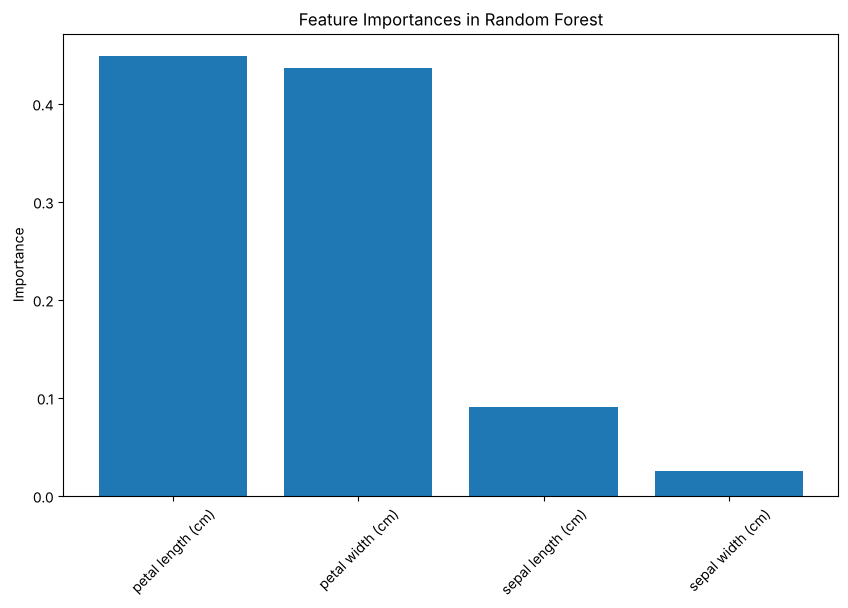

In [ ]:
# Load the libraries
import matplotlib.pyplot as plt

# Calculate feature importance
importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1]

# Plot the feature importance
plt.figure(figsize=(10,6))
plt.title("Feature Importances in Random Forest")
plt.bar(range(X.shape[1]), importances[indices], align="center")
plt.xticks(range(X.shape[1]), [iris.feature_names[i] for i in indices], rotation=45)
plt.ylabel("Importance")
plt.show()

In [ ]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(rf_clf, X_test, y_test, n_repeats=30, random_state=2024)
display(pd.DataFrame({
    'MDI (feature_importances_)': rf_clf.feature_importances_,
    'Permutation importance (test)': perm.importances_mean,
}, index=iris.feature_names).round(3).sort_values('MDI (feature_importances_)', ascending=False))

,MDI (feature_importances_),Permutation importance (test)
petal length (cm),0.449,0.200
petal width (cm),0.436,0.452
sepal length (cm),0.090,-0.003
sepal width (cm),0.025,-0.009


**Interpretasi.**
- Random Forest mencapai akurasi uji **0,911** (41 dari 45), lebih baik daripada satu pohon (0,867). Dua kesalahan *virginica* → *versicolor* berhasil diperbaiki oleh "suara mayoritas" 100 pohon yang beragam — contoh nyata penurunan varians oleh bagging.
- **OOB score 0,962** dihitung tanpa data uji sama sekali, memakai sampel yang tidak terambil di bootstrap setiap pohon. OOB lebih tinggi daripada akurasi uji di sini, karena data uji 45 sampel ini kebetulan berisi beberapa bunga yang sulit dibedakan.
- **Feature importance:** fitur kelopak (*petal length/width*) mendominasi (MDI ≈ 0,45 dan 0,44), sedangkan fitur sepal hampir tidak berperan — konsisten dengan pairplot di Bab 6. *Permutation importance* bahkan memberi nilai ≈0 (sedikit negatif) untuk fitur sepal, artinya mengacak fitur tersebut tidak menurunkan akurasi uji sama sekali. Perbedaan MDI vs permutation untuk *petal length* (0,45 vs 0,20) terjadi karena *petal length* dan *petal width* sangat berkorelasi: ketika satu diacak, model masih bisa mengandalkan yang lain.

## Resep 3 — Gradient Boosted Machines

### Teori
Boosting membangun model **aditif** secara berurutan:
$$F_m(\mathbf x) = F_{m-1}(\mathbf x) + \nu\,h_m(\mathbf x),$$
dengan $h_m$ sebuah pohon kecil (*weak learner*) dan $\nu$ = **learning rate** (*shrinkage*).

**Gradient Boosting (Friedman 2001)** memandang ini sebagai *gradient descent* di ruang fungsi. Pada iterasi $m$:
1. Hitung **pseudo-residual** = negatif gradien loss terhadap prediksi saat ini:
$$r_{im} = -\left[\frac{\partial L\big(y_i, F(\mathbf x_i)\big)}{\partial F(\mathbf x_i)}\right]_{F=F_{m-1}}$$
Untuk squared error $L = \frac12(y-F)^2$, ini tepat sama dengan residual biasa $y_i - F_{m-1}(\mathbf x_i)$; untuk klasifikasi dipakai log-loss.
2. Latih pohon $h_m$ untuk memprediksi $r_{im}$.
3. Perbarui model $F_m = F_{m-1} + \nu h_m$.

Bagging terutama menurunkan **varians** (pohon dalam, independen), sedangkan boosting terutama menurunkan **bias** (pohon dangkal, berurutan, masing-masing memperbaiki kesalahan sebelumnya).

**Trade-off `learning_rate` vs `n_estimators`:** $\nu$ kecil membutuhkan lebih banyak pohon tetapi biasanya generalisasinya lebih baik. Berbeda dengan Random Forest, menambah pohon pada boosting **bisa** menyebabkan overfitting — gunakan *early stopping* (`n_iter_no_change`) atau validasi. Untuk data besar, `HistGradientBoostingClassifier` jauh lebih cepat.

In [ ]:
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [ ]:
# Instantiate the model
gbm_clf = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.2, random_state=2024)

# Fit the model to the training data
gbm_clf.fit(X_train, y_train)

# Generate predictions
y_pred = gbm_clf.predict(X_test)

# Evaluate the model
report = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()

# Stylize the DataFrame
styled_df = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
styled_df

,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


In [ ]:
from sklearn.metrics import accuracy_score
print('Akurasi GBM (1000 pohon, lr=0.2): %.3f' % accuracy_score(y_test, y_pred))
print('Akurasi latih                   : %.3f' % gbm_clf.score(X_train, y_train))
print('Jumlah pohon total: %d (= %d iterasi x %d kelas)' % (gbm_clf.estimators_.size, gbm_clf.n_estimators_, gbm_clf.estimators_.shape[1]))

# staged_predict: akurasi uji setelah setiap iterasi boosting
staged = [accuracy_score(y_test, p) for p in gbm_clf.staged_predict(X_test)]
for k in [1, 5, 10, 50, 100, 500, 1000]:
    print(f'  setelah {k:>4} iterasi -> akurasi uji {staged[k-1]:.3f}')

Akurasi GBM (1000 pohon, lr=0.2): 0.867
Akurasi latih                   : 1.000
Jumlah pohon total: 3000 (= 1000 iterasi x 3 kelas)


  setelah    1 iterasi -> akurasi uji 0.867
  setelah    5 iterasi -> akurasi uji 0.867
  setelah   10 iterasi -> akurasi uji 0.867
  setelah   50 iterasi -> akurasi uji 0.867
  setelah  100 iterasi -> akurasi uji 0.867
  setelah  500 iterasi -> akurasi uji 0.867
  setelah 1000 iterasi -> akurasi uji 0.867


**Interpretasi.** Gradient Boosting dengan 1000 iterasi dan `learning_rate=0.2` memperoleh akurasi uji **0,867**, lebih rendah daripada Random Forest dan sama dengan satu pohon. Untuk 3 kelas, scikit-learn membangun satu pohon regresi per kelas per iterasi (*one-vs-all* dalam ruang gradien), sehingga total ada 3.000 pohon.

Akurasi uji **konstan 0,867 sejak iterasi pertama hingga ke-1000**. Artinya pohon-pohon tambahan hanya terus "mempertajam" probabilitas pada data latih (akurasi latih 1,000), tetapi tidak mengubah keputusan untuk 6 sampel uji yang sulit. Ribuan iterasi pada data sebesar ini hanya membuang waktu komputasi; *early stopping* atau `n_estimators` yang jauh lebih kecil akan memberi hasil yang sama dengan biaya jauh lebih rendah.

## Resep 4 — Tuning Hyperparameter Pohon dan Ensemble

### Teori
Hyperparameter penting:

| Hyperparameter | Model | Efek |
|---|---|---|
| `max_depth` | semua | kedalaman pohon; kecil → bias tinggi, besar → varians tinggi |
| `min_samples_leaf`, `min_samples_split` | semua | ukuran minimum daun/simpul; mencegah daun kecil yang menghafal noise |
| `n_estimators` | RF, GB | jumlah pohon. RF: lebih banyak hampir tidak pernah merugikan (hanya lebih lambat). GB: terlalu banyak bisa overfit |
| `learning_rate` | GB | besarnya kontribusi setiap pohon; berinteraksi kuat dengan `n_estimators` |
| `max_features` | RF | jumlah fitur acak per pemisahan; kecil → pohon lebih beragam |
| `subsample` | GB | < 1 → *stochastic gradient boosting*, menambah regularisasi |

Grid buku berisi 3 × 3 × 3 = 27 kombinasi × 5 fold = 135 kali pelatihan.

In [ ]:
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [ ]:
# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2]
}

# Set up GridSearchCV()
grid_search = GridSearchCV(GradientBoostingClassifier(random_state=2024),
                           param_grid,
                           cv=5,
                           scoring='accuracy')

# Fit GridSearchCV() to training data
grid_search.fit(X_train, y_train)

# Identify the best parameters
print(f'Best Parameters: {grid_search.best_params_}')

# Evaluate the best model
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

# Generate classification report
report = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()

# Stylize the DataFrame
styled_df = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

styled_df

Best Parameters: {'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 50}


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


In [ ]:
print('Skor CV terbaik: %.3f' % grid_search.best_score_)
print('Akurasi uji model terbaik: %.3f' % accuracy_score(y_test, y_pred))
print('Jumlah kombinasi dengan skor CV = skor terbaik:',
      int((pd.DataFrame(grid_search.cv_results_)['rank_test_score'] == 1).sum()))

Skor CV terbaik: 0.981
Akurasi uji model terbaik: 0.867
Jumlah kombinasi dengan skor CV = skor terbaik: 20


### Visualisasi hasil grid search
Heatmap berikut merata-ratakan skor CV atas ketiga nilai `learning_rate` untuk setiap kombinasi `max_depth` × `n_estimators`.

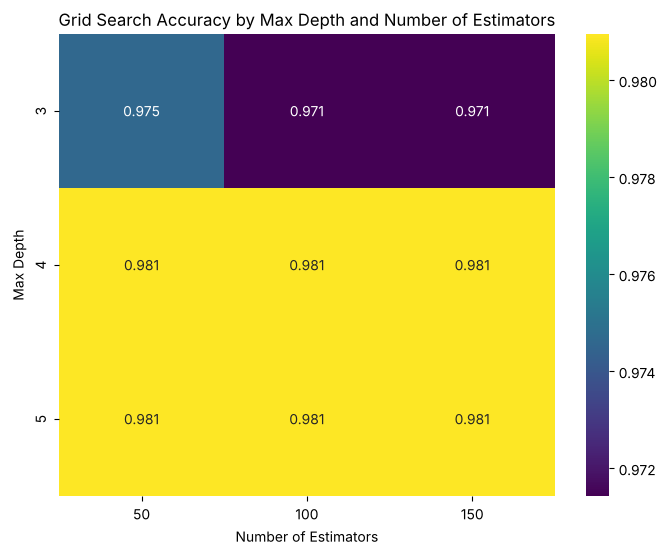

In [ ]:
# Load the libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Create a pivot table
results = pd.DataFrame(grid_search.cv_results_)
pivot_table = results.pivot_table(values='mean_test_score',
                                  index='param_max_depth',
                                  columns='param_n_estimators')

# Plot the heatmap
plt.figure(figsize=(8,6))
sns.heatmap(pivot_table, annot=True, fmt='.3f', cmap='viridis')
plt.title('Grid Search Accuracy by Max Depth and Number of Estimators')
plt.xlabel('Number of Estimators')
plt.ylabel('Max Depth')
plt.show()

**Interpretasi.** Skor CV terbaik 0,981, tetapi **20 dari 27 kombinasi** memiliki skor CV yang sama persis. Grid search lalu sekadar memilih kombinasi pertama di antara yang seri (`learning_rate=0.01`, `max_depth=4`, `n_estimators=50`) — pilihan ini bukan "pemenang" yang sesungguhnya. Heatmap yang hampir seragam memperlihatkan hal yang sama: pada Iris, hyperparameter Gradient Boosting hampir tidak berpengaruh.

Akurasi uji model terpilih tetap 0,867 — keenam sampel sulit tetap salah. Pelajaran: tuning tidak bisa menutupi keterbatasan informasi di dalam data. Ketika banyak konfigurasi setara, pilih yang paling **sederhana/murah** (misalnya `n_estimators` terkecil).

## Resep 5 — Membandingkan Metode Ensemble

### Teori
**Stacking (Wolpert 1992)** melatih beberapa *base model* yang berbeda, lalu sebuah **meta-model** belajar cara terbaik menggabungkan prediksi mereka. Agar meta-model tidak belajar dari prediksi yang "terlalu bagus" (base model memprediksi data yang dipakainya untuk berlatih), `StackingClassifier` memakai **prediksi cross-validated** (`cv=5`): setiap base model memprediksi fold yang tidak dipakainya saat berlatih, dan prediksi *out-of-fold* inilah yang menjadi fitur untuk meta-model.

| | Bagging (RF) | Boosting (GB) | Stacking |
|---|---|---|---|
| Cara melatih | paralel, independen | berurutan | base model paralel + meta-model |
| Base model | sejenis (pohon dalam) | sejenis (pohon dangkal) | bisa beragam |
| Terutama mengurangi | varians | bias | keduanya (memanfaatkan keragaman model) |
| Risiko | – | overfitting jika terlalu banyak iterasi | kompleks, lambat |

Stacking paling bermanfaat bila base model **beragam** dan membuat kesalahan yang berbeda-beda.

In [ ]:
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [ ]:
# Instantiate models
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)
gb_clf = GradientBoostingClassifier(n_estimators=100, random_state=2024)
stacking_clf = StackingClassifier(
    estimators=[('rf', rf_clf), ('gb', gb_clf)],
    final_estimator=LogisticRegression(),
    cv=5
)
# Fit the models
rf_clf.fit(X_train, y_train)
gb_clf.fit(X_train, y_train)
stacking_clf.fit(X_train, y_train)

# Generate predictions
rf_pred = rf_clf.predict(X_test)
gb_pred = gb_clf.predict(X_test)
stacking_pred = stacking_clf.predict(X_test)

# Evaluate the models
rf_accuracy = accuracy_score(y_test, rf_pred)
gb_accuracy = accuracy_score(y_test, gb_pred)
stacking_accuracy = accuracy_score(y_test, stacking_pred)

# Print the accuracy scores
print(f'Random Forest Accuracy: {rf_accuracy:.2f}')
print(f'Gradient Boosting Accuracy: {gb_accuracy:.2f}')
print(f'Stacking Accuracy: {stacking_accuracy:.2f}')

Random Forest Accuracy: 0.91
Gradient Boosting Accuracy: 0.87
Stacking Accuracy: 0.87


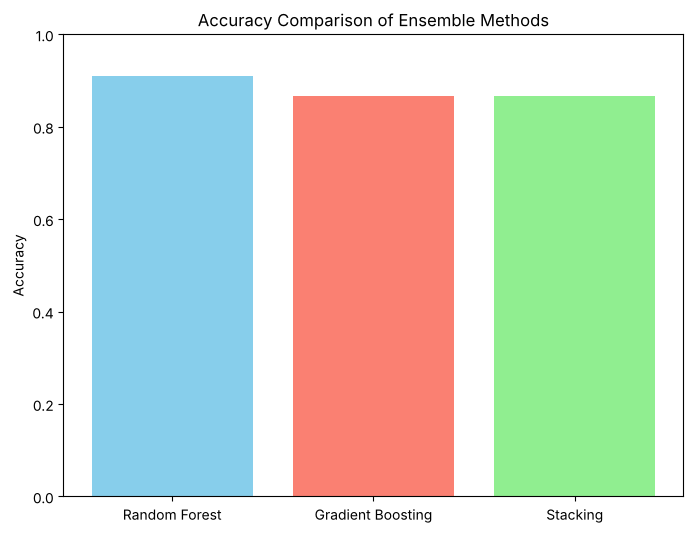

In [ ]:
# Load the libraries
import matplotlib.pyplot as plt

# Create a bar plot
methods = ['Random Forest', 'Gradient Boosting', 'Stacking']
accuracies = [rf_accuracy, gb_accuracy, stacking_accuracy]

# Plot the bar plot
plt.figure(figsize=(8, 6))
plt.bar(methods, accuracies, color=['skyblue', 'salmon', 'lightgreen'])
plt.title('Accuracy Comparison of Ensemble Methods')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()

**Interpretasi.** Random Forest 0,91, Gradient Boosting 0,87, Stacking 0,87. Stacking **tidak** mengungguli base model terbaiknya. Ada dua penyebab:
1. Kedua base model sama-sama berbasis pohon, sehingga cenderung salah pada sampel yang **sama**; meta-model tidak punya "pendapat berbeda" untuk dimanfaatkan. Stacking paling efektif bila base model beragam (misalnya pohon + SVM + KNN).
2. Data latih hanya 105 sampel; meta-model dilatih dari prediksi *out-of-fold* yang jumlahnya sama sedikitnya.

Selisih antar-model di sini hanya 2 sampel dari 45. Untuk perbandingan yang meyakinkan, gunakan cross-validation berulang (Bab 12) atau dataset yang lebih besar — seperti pada Latihan 3.

## Latihan Praktik

### Latihan 1 — Pohon keputusan pada dataset Wine

In [ ]:
# Load libraries
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

# Load the dataset
wine = load_wine()
X = wine.data
y = wine.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train the classifier
clf = DecisionTreeClassifier(random_state=2024)
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

#Evaluate performance
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.78      0.88        18
           1       0.79      0.95      0.86        20
           2       0.94      0.94      0.94        16

    accuracy                           0.89        54
   macro avg       0.91      0.89      0.89        54
weighted avg       0.90      0.89      0.89        54



**Interpretasi.** Pohon keputusan pada Wine mencapai akurasi 0,89 (48 dari 54). Pola kesalahannya menarik: kelas 0 memiliki precision 1,00 tetapi recall hanya 0,78 (4 dari 18 sampel kelas 0 terlewat), sedangkan kelas 1 memiliki recall tinggi (0,95) tetapi precision 0,79 — banyak sampel kelas lain yang "jatuh" ke kelas 1. Satu pohon dengan batas sejajar sumbu kesulitan menangkap batas antar-kultivar yang miring. Sebagai pembanding, di Bab 3 LDA memisahkan ketiga kelas Wine dengan sangat bersih, karena LDA memakai kombinasi linear fitur.

### Latihan 2 — Tuning Random Forest pada Breast Cancer

In [ ]:
# Load libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Define hyperparameter grid and perform grid search
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 7],
    'max_features': ['sqrt', 'log2']
}
grid_search = GridSearchCV(RandomForestClassifier(random_state=2024), param_grid, cv=5, error_score='raise')
grid_search.fit(X_train, y_train)

# Evaluate the best model
best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Best Parameters: {grid_search.best_params_}')
print(f'Accuracy: {accuracy:.2f}')

Best Parameters: {'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 150}
Accuracy: 0.95


**Interpretasi.** Grid search memilih `max_depth=5`, `max_features='sqrt'`, `n_estimators=150` dengan akurasi uji 0,95. Random Forest tidak membutuhkan scaling, sehingga — berbeda dengan KNN, SVM, dan regresi logistik di bab-bab sebelumnya — hasil yang baik diperoleh langsung dari data mentah Breast Cancer. Kedalaman maksimum yang terpilih (5) relatif dangkal, menandakan sedikit regularisasi pada pohon-pohon individual membantu generalisasi. Argumen `error_score='raise'` membuat grid search langsung berhenti dengan pesan error jika ada kombinasi yang gagal dilatih, alih-alih diam-diam memberinya skor NaN.

### Latihan 3 — Gradient Boosting vs Random Forest pada Digits

In [ ]:
# Load libraries
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
digits = load_digits()
X = digits.data
y = digits.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train models
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)
gb_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=2024)
rf_clf.fit(X_train, y_train)
gb_clf.fit(X_train, y_train)

# Make predictions and evaluate
rf_pred = rf_clf.predict(X_test)
gb_pred = gb_clf.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)
gb_accuracy = accuracy_score(y_test, gb_pred)
print(f'Random Forest Accuracy: {rf_accuracy:.2f}')
print(f'Gradient Boosting Accuracy: {gb_accuracy:.2f}')

Random Forest Accuracy: 0.97
Gradient Boosting Accuracy: 0.96


In [ ]:
import time
for name, model in [('Random Forest', RandomForestClassifier(n_estimators=100, random_state=2024)),
                    ('Gradient Boosting', GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=2024))]:
    t0 = time.time(); model.fit(X_train, y_train)
    print(f'{name:<18} waktu latih: {time.time() - t0:5.2f} detik')

Random Forest      waktu latih:  0.34 detik


Gradient Boosting  waktu latih:  5.61 detik


**Interpretasi.** Pada Digits (1.797 gambar, 64 fitur, 10 kelas), Random Forest (0,97) sedikit mengungguli Gradient Boosting (0,96), dan dilatih sekitar **15–20× lebih cepat**. Dua alasan:
1. Pohon-pohon Random Forest independen sehingga mudah diparalelkan, dan pemilihan fitur acak membuat setiap pemisahan murah. Gradient Boosting harus membangun pohon secara **berurutan**, dan untuk 10 kelas membangun 10 pohon per iterasi (100 iterasi × 10 kelas = 1.000 pohon).
2. Dengan pengaturan default (`learning_rate=0.1`, 100 iterasi, `max_depth=3`), Gradient Boosting belum tentu optimal; dengan tuning (atau memakai `HistGradientBoostingClassifier`) boosting sering bisa menyamai atau melampaui Random Forest.

Kesimpulan praktis: Random Forest adalah *baseline* yang kuat, cepat, dan minim tuning; Gradient Boosting berpotensi lebih akurat tetapi butuh tuning yang lebih teliti.

## Kesimpulan Bab 8

- **Pohon keputusan** memisahkan data secara rekursif untuk menurunkan impurity (Gini/entropi). Mudah diinterpretasikan, tetapi satu pohon rawan overfitting dan tidak stabil.
- **Random Forest** = bagging + subset fitur acak per pemisahan → menurunkan korelasi antar-pohon sehingga **varians** turun. Menyediakan OOB score dan feature importance.
- **Gradient Boosting** menambahkan pohon dangkal secara berurutan yang mengikuti negatif gradien loss → menurunkan **bias**. `learning_rate` dan `n_estimators` harus di-tuning bersama.
- **Stacking** memakai meta-model atas prediksi out-of-fold beberapa base model.
- Model berbasis pohon tidak memerlukan scaling fitur.
- Pada dataset kecil seperti Iris, perbedaan antar-ensemble sering hanya 1–2 sampel; gunakan cross-validation dan data yang lebih besar untuk perbandingan yang meyakinkan.